In [1]:
import os
import torch
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
from skimage.color import deltaE_ciede2000, rgb2lab
from tqdm import tqdm
from GAN.src.model import build_res_unet, MainModel
from GAN.src.colorize import test_colorizer, colorize
from GAN.src.visualize import plot_finetuning_loss, visualize
from src.evaluate import avg_deltaE, mean_chroma, mse

/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c106detail19maybe_wrap_dim_slowIxEET_S2_S2_b
  Referenced from: <9B280146-BBD7-3F77-9873-F9740F2A5329> /Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/image.so
  Expected in:     <408F81C0-C6C8-33EF-B02E-B683F7178A71> /Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torch/lib/libc10.dylib'If you don't plan on using image functional

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Visualizations

### CNN

### conditional GAN

In [3]:
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [4]:
# the base model
model1 = MainModel(net_G = net_G1)
model1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [5]:
# the finetuned model
model2 = MainModel(net_G = net_G2)
model2.load_state_dict(torch.load("GAN/src/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/skimage/color/colorconv.py:1109: UserWarning: Color data out of range: Z < 0 in 1 pixels
  return xyz2rgb(lab2xyz(lab, illuminant, observer))


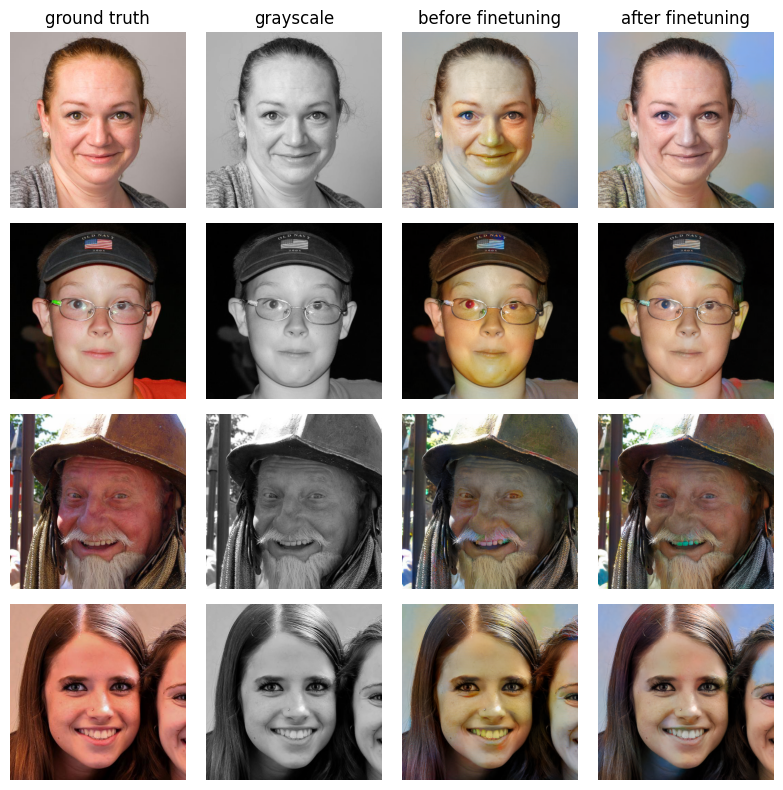

In [6]:
visualize(model1,model2, "data/faces_val", seed = 55)

# Evaluation

In [25]:
avg_deltaE(model1, "GAN/data/faces_val", model_type="GAN", seed = 13, size = 50)

  0%|          | 0/50 [00:00<?, ?it/s]

 96%|█████████▌| 48/50 [01:33<00:03,  1.88s/it]/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/skimage/color/colorconv.py:1109: UserWarning: Color data out of range: Z < 0 in 1 pixels
  return xyz2rgb(lab2xyz(lab, illuminant, observer))
100%|██████████| 50/50 [01:37<00:00,  1.95s/it]


11.223632033161056

In [8]:
avg_deltaE(model2, "GAN/data/faces_val", model_type="GAN", seed = 13, size = 50)

100%|██████████| 10/10 [00:19<00:00,  1.95s/it]


8.361004621762401

In [9]:
mean_chroma(model2, "GAN/data/faces_val", seed = 13, size = 50)

100%|██████████| 10/10 [00:17<00:00,  1.75s/it]


34.03122406005859

In [ ]:
mse(model1, "GAN/data/faces_val", model_type="GAN", seed = 13, size = 50)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:20<00:00,  2.09s/it]


452.4047543843587

In [11]:
mse(model2, "GAN/data/faces_val", model_type="GAN", seed = 13, size = 50)

100%|██████████| 10/10 [00:18<00:00,  1.81s/it]


452.10172831217443